# 查看监控指标
在添加LangSmith相关环境变量后，程序通过load_dotenv加载，然后运行Langchain代码，LangSmith会自动记录运行指标，同步到后台

![image.png](images/LangSmithconfig.png)

## 运行任意Langchain程序

In [1]:
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
# 将env文件中的变量加载为环境变量
#override=True：表示.env优先
load_dotenv(override=True)
DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")
model = ChatDeepSeek(
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,
    model_name="deepseek-v4-flash"
)
print(model.invoke("你好"))

content='你好！很高兴见到你 😊 有什么我可以帮你的吗？无论是聊天、解答问题、帮忙写作、翻译，还是其他任何事情，都可以告诉我。' additional_kwargs={'refusal': None, 'reasoning_content': 'The user just said "你好" (Hello) in Chinese. I should respond warmly in Chinese, greet them, and offer to help. Keep it friendly and concise.'} response_metadata={'token_usage': {'completion_tokens': 67, 'prompt_tokens': 31, 'total_tokens': 98, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 34, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 31}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': 'a744115d-2006-4e1f-9e2c-f01547dd03c8', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a19a44-3854-76a6-bc39-7a906df552b2-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 31, 'output_tokens'

![image.png](images/LangSmith01.png)
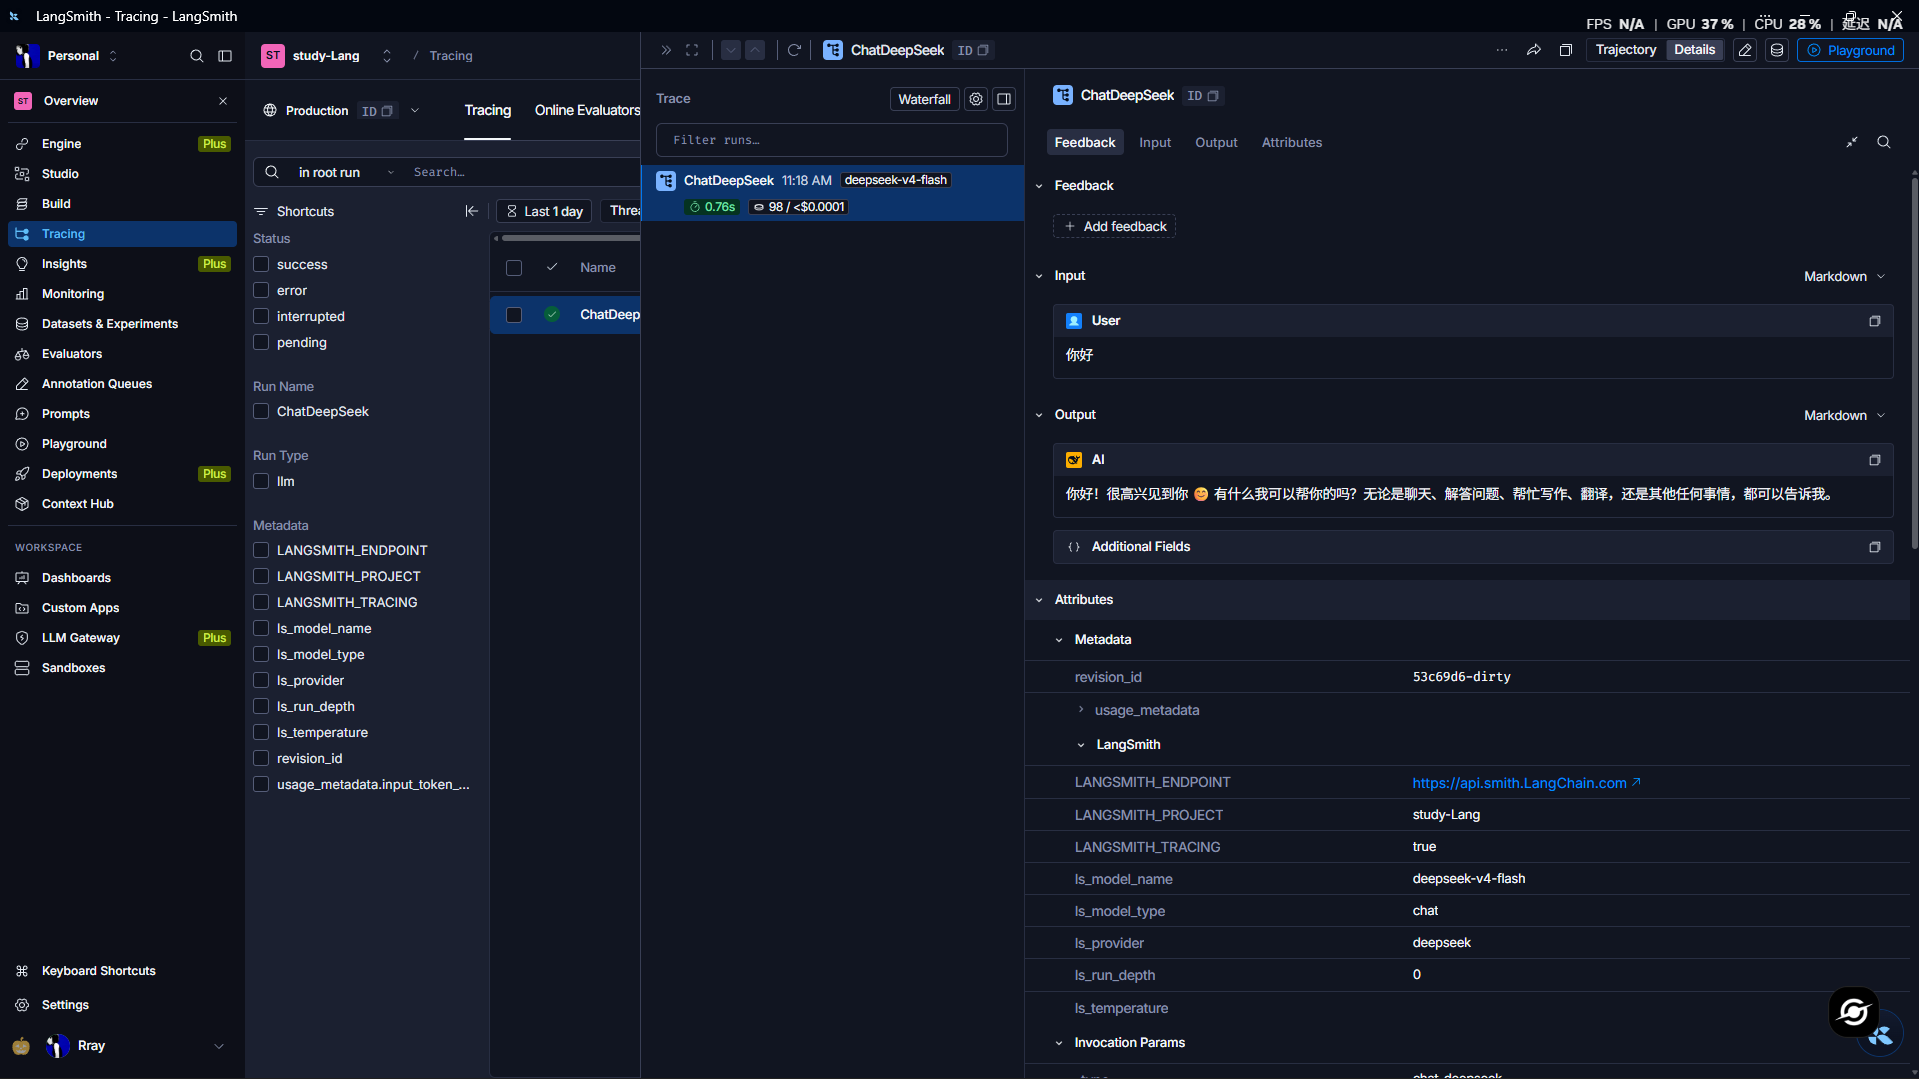

In [4]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model
# 将env文件中的变量加载为环境变量
#override=True：表示.env优先
load_dotenv(override=True)
DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")
model = init_chat_model(
    api_key=DEEPSEEK_API_KEY,
    api_base=DEEPSEEK_BASE_URL,
    model="deepseek-v4-flash"
)
print(model.invoke("你好"))

content='你好！很高兴见到你 😊 有什么我可以帮你的吗？无论是回答问题、聊天，还是需要帮忙处理文字、分析问题，都可以跟我说。' additional_kwargs={'refusal': None, 'reasoning_content': 'The user just said "你好" (Hello) in Chinese. I should respond warmly in Chinese and offer help. Keep it concise and friendly.'} response_metadata={'token_usage': {'completion_tokens': 61, 'prompt_tokens': 31, 'total_tokens': 92, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 29, 'rejected_prediction_tokens': None}, 'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 31}, 'model_provider': 'deepseek', 'model_name': 'deepseek-flash', 'system_fingerprint': 'bc19ba97cbe016479903222bb1578db6', 'id': 'e57e7890-f87e-428e-8b53-a9a0b8e340a9', 'finish_reason': 'stop', 'logprobs': None} id='lc_run--01a19a4a-6583-733c-a41d-2d5f7752a86f-0' tool_calls=[] invalid_tool_calls=[] usage_metadata={'input_tokens': 31, 'output_tokens': 61, 'total_toke

![image.png](images/LangSmith02.png)
![image.png](images/LangSmith03.png)

In [5]:
from langchain.chat_models import init_chat_model
from dotenv import load_dotenv
import os
from rich import print as rprint
# 从.env文件中加载环境变量
load_dotenv(override=True)
DEEPSEEK_API_KEY = os.getenv("DEEPSEEK_API_KEY")
DEEPSEEK_BASE_URL = os.getenv("DEEPSEEK_BASE_URL")
# 1. 初始化模型
model = init_chat_model(
    model="deepseek-v4-flash",
    model_provider="deepseek",
    api_key=DEEPSEEK_API_KEY,
    base_url=DEEPSEEK_BASE_URL,
    temperature=0.2,
    max_tokens=500,
    # 指定可调整参数
    configurable_fields=("model", "model_provider", "temperature","max_tokens"),
)
# 2. 准备 config 字典
config = {
    "run_name": "joke_generation", # 在LangSmith中这次运行会显示为
    "joke_generation"
    "tags": ["my_tag1", "my_tag2"], # 打上标签便于分类查找
    "metadata": {
        "user_id": "shkstart", # 记录用户ID
        "session_id": "sess_123" # 记录会话ID
    },
    "configurable": {
        "model": "deepseek-v4-pro", # 配置模型参数
        "model_provider": "openai", # 配置模型提供商参数
        "temperature": 0.7, # 配置温度参数
        "max_tokens": 1000 # 配置最大令牌数
    }
}
# 3. 调用模型并传入config
response = model.invoke(
    "1 + 2 = ？",
    config=config
)
rprint(response)

AIMessage(
    content='3',
    additional_kwargs={'refusal': None},
    response_metadata={
        'token_usage': {
            'completion_tokens': 40,
            'prompt_tokens': 90,
            'total_tokens': 130,
            'completion_tokens_details': {
                'accepted_prediction_tokens': None,
                'audio_tokens': None,
                'reasoning_tokens': 38,
                'rejected_prediction_tokens': None
            },
            'prompt_tokens_details': {'audio_tokens': None, 'cached_tokens': 0},
            'prompt_cache_hit_tokens': 0,
            'prompt_cache_miss_tokens': 90
        },
        'model_provider': 'openai',
        'model_name': 'deepseek-v4-pro',
        'system_fingerprint': 'a307abda487cd1b463329ccb945ce396',
        'id': '82547169-c722-487f-a79d-7684a0b1e1ba',
        'finish_reason': 'stop',
        'logprobs': None
    },
    id='lc_run--01a19a4e-26b3-729a-9e08-ce63e6fde2cc-0',
    tool_calls=[],
    invalid_tool_calls=[],
    usage_metadata={
        'input_tokens': 90,
        'output_tokens': 40,
        'total_tokens': 130,
        'input_token_details': {'cache_read': 0},
        'output_token_details': {'reasoning': 38}
    }
)

![image.png](images/LangSmith04.png)